In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [2]:
import zipfile
import os

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall('/content/sales_data')

print("Dataset extracted successfully!")
print("Files:", os.listdir('/content/sales_data'))

Dataset extracted successfully!
Files: ['Advertising.csv']


In [3]:
import pandas as pd
import numpy as np

file_path = '/content/sales_data/Advertising.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Records: 0

Cleaned Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None

Statistical Summary:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000



Correlation Matrix:


,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


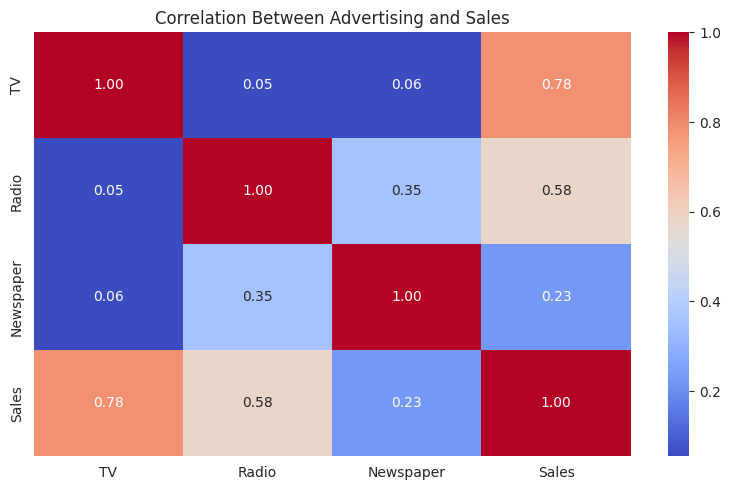

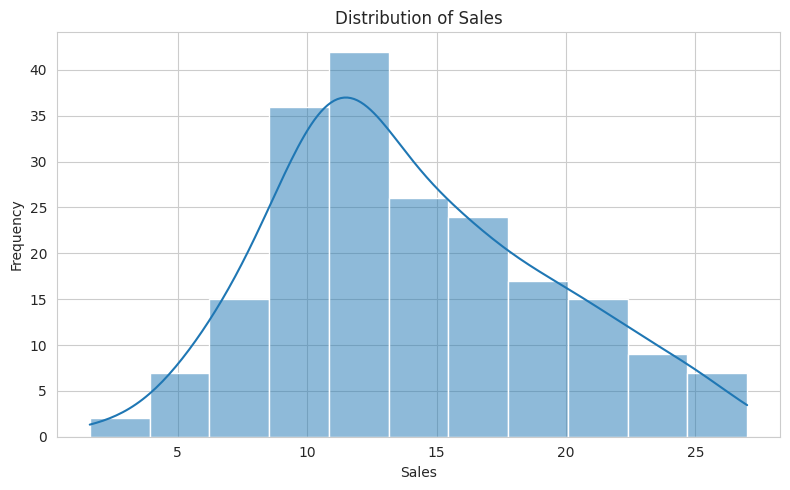

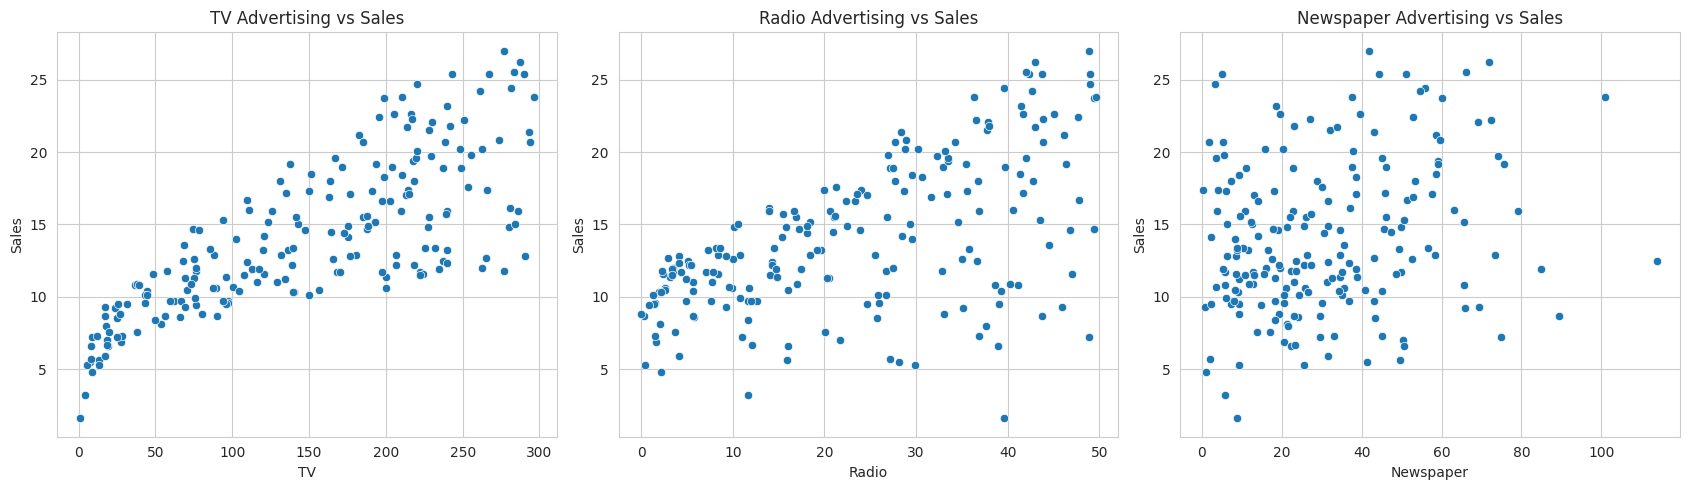


Final Cleaned Dataset Shape: (200, 4)

Data Cleaning and EDA Completed Successfully!


In [4]:

# ==========================================
# STEP 3: DATA CLEANING AND EDA
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style("whitegrid")

# 1. Remove unnecessary index column
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

# 2. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 3. Remove duplicate records
print("\nDuplicate Records:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# 4. Handle missing values if present
df.dropna(inplace=True)

# 5. Dataset information
print("\nCleaned Dataset Information:")
print(df.info())

# 6. Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# 7. Correlation analysis
print("\nCorrelation Matrix:")
correlation = df.corr()
display(correlation)

# 8. Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Between Advertising and Sales")
plt.tight_layout()
plt.show()

# 9. Sales distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['Sales'], kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 10. Advertising impact on sales
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.scatterplot(data=df, x='TV', y='Sales', ax=axes[0])
axes[0].set_title("TV Advertising vs Sales")

sns.scatterplot(data=df, x='Radio', y='Sales', ax=axes[1])
axes[1].set_title("Radio Advertising vs Sales")

sns.scatterplot(data=df, x='Newspaper', y='Sales', ax=axes[2])
axes[2].set_title("Newspaper Advertising vs Sales")

plt.tight_layout()
plt.show()

# 11. Final dataset shape
print("\nFinal Cleaned Dataset Shape:", df.shape)
print("\nData Cleaning and EDA Completed Successfully!")


Training records: 160
Testing records: 40

Linear Regression Model Trained Successfully!

========== MODEL PERFORMANCE ==========
Mean Absolute Error (MAE): 1.461
Mean Squared Error (MSE): 3.174
Root Mean Squared Error (RMSE): 1.782
R2 Score: 0.8994
Model Accuracy (R2 %): 89.94 %

Actual vs Predicted Sales:


,Actual Sales,Predicted Sales
0,16.9,16.408024
1,22.4,20.889882
2,21.4,21.553843
3,7.3,10.608503
4,24.7,22.112373
5,12.6,13.105592
6,22.3,21.057192
7,8.4,7.461010
8,11.5,13.606346
9,14.9,15.155070


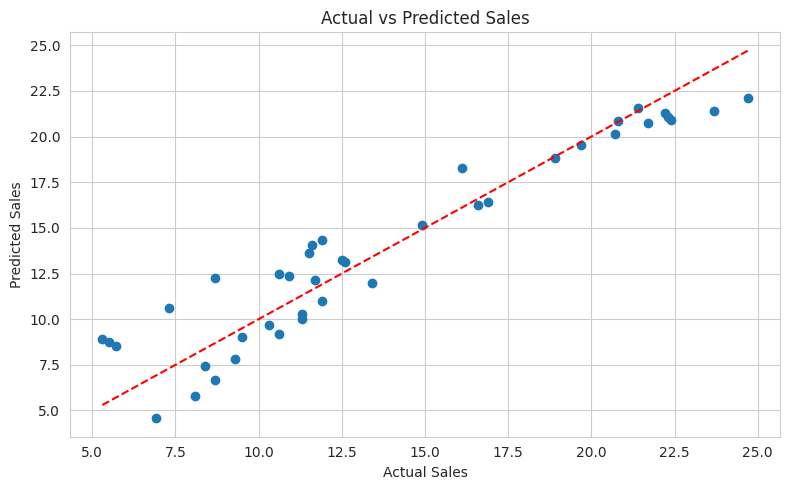


Advertising Impact:


,Advertising Platform,Coefficient
0,TV,0.044730
1,Radio,0.189195
2,Newspaper,0.002761


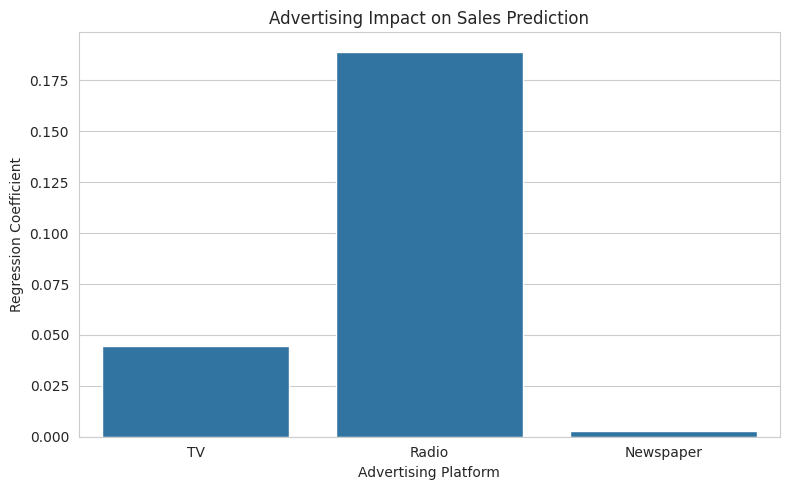


========== NEW SALES PREDICTION ==========
TV Advertising Budget: 200
Radio Advertising Budget: 30
Newspaper Advertising Budget: 40
Predicted Sales: 17.71

Sales Prediction Completed Successfully!


In [5]:

# ==========================================
# STEP 4: SALES PREDICTION USING LINEAR REGRESSION
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Feature Selection
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 2. Split Dataset into Training and Testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

# 3. Create Linear Regression Model
model = LinearRegression()

# 4. Train the Model
model.fit(X_train, y_train)

print("\nLinear Regression Model Trained Successfully!")

# 5. Predict Sales
y_pred = model.predict(X_test)

# 6. Model Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n========== MODEL PERFORMANCE ==========")
print("Mean Absolute Error (MAE):", round(mae, 3))
print("Mean Squared Error (MSE):", round(mse, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R2 Score:", round(r2, 4))
print("Model Accuracy (R2 %):", round(r2 * 100, 2), "%")

# 7. Compare Actual and Predicted Sales
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': y_pred
})

print("\nActual vs Predicted Sales:")
display(comparison.head(10))

# 8. Actual vs Predicted Visualization
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.tight_layout()
plt.show()

# 9. Feature Importance using Regression Coefficients
importance = pd.DataFrame({
    'Advertising Platform': X.columns,
    'Coefficient': model.coef_
})

print("\nAdvertising Impact:")
display(importance)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance,
    x='Advertising Platform',
    y='Coefficient'
)
plt.title("Advertising Impact on Sales Prediction")
plt.ylabel("Regression Coefficient")
plt.tight_layout()
plt.show()

# 10. Predict Sales for New Advertising Budget
new_data = pd.DataFrame({
    'TV': [200],
    'Radio': [30],
    'Newspaper': [40]
})

predicted_sales = model.predict(new_data)

print("\n========== NEW SALES PREDICTION ==========")
print("TV Advertising Budget: 200")
print("Radio Advertising Budget: 30")
print("Newspaper Advertising Budget: 40")
print("Predicted Sales:", round(predicted_sales[0], 2))

print("\nSales Prediction Completed Successfully!")


In [6]:

# ==========================================
# STEP 5: BUSINESS INSIGHTS AND CONCLUSION
# ==========================================

print("=" * 55)
print("       SALES PREDICTION - BUSINESS INSIGHTS")
print("=" * 55)

# 1. Model Performance
print("\n1. MODEL PERFORMANCE")
print("-" * 35)

print(f"MAE  : {mae:.3f}")
print(f"MSE  : {mse:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R2 Score : {r2:.4f}")
print(f"Model R2 Percentage : {r2 * 100:.2f}%")

# 2. Advertising Platform Analysis
print("\n2. ADVERTISING PLATFORM ANALYSIS")
print("-" * 35)

for index, row in importance.iterrows():
    print(f"{row['Advertising Platform']}: {row['Coefficient']:.5f}")

best_platform = importance.loc[
    importance['Coefficient'].idxmax(),
    'Advertising Platform'
]

print(f"\nHighest estimated coefficient: {best_platform}")

# 3. Correlation Analysis
print("\n3. CORRELATION WITH SALES")
print("-" * 35)

sales_corr = df.corr()['Sales'].drop('Sales').sort_values(ascending=False)

for platform, value in sales_corr.items():
    print(f"{platform}: {value:.3f}")

# 4. Business Recommendations
print("\n4. BUSINESS AND MARKETING RECOMMENDATIONS")
print("-" * 35)

print("1. Focus on advertising platforms that show stronger")
print("   relationships with sales.")
print("2. Consider Radio advertising because it has the")
print("   highest estimated regression coefficient.")
print("3. Continue using TV advertising as it shows a")
print("   strong positive relationship with sales.")
print("4. Evaluate Newspaper advertising costs and")
print("   performance before allocating large budgets.")
print("5. Monitor advertising expenditure and sales")
print("   regularly to improve marketing decisions.")
print("6. Use prediction models to support future")
print("   advertising budget planning.")

# 5. Project Conclusion
print("\n5. PROJECT CONCLUSION")
print("-" * 35)

print("Sales Prediction using Python was successfully completed.")
print("The dataset was cleaned and analyzed using Pandas and NumPy.")
print("Exploratory Data Analysis was performed using visualizations.")
print("A Multiple Linear Regression model was trained.")
print("Model performance was evaluated using MAE, MSE, RMSE and R2.")
print("The model can estimate sales based on advertising expenditure.")

print("\n" + "=" * 55)
print("       PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 55)


       SALES PREDICTION - BUSINESS INSIGHTS

1. MODEL PERFORMANCE
-----------------------------------
MAE  : 1.461
MSE  : 3.174
RMSE : 1.782
R2 Score : 0.8994
Model R2 Percentage : 89.94%

2. ADVERTISING PLATFORM ANALYSIS
-----------------------------------
TV: 0.04473
Radio: 0.18920
Newspaper: 0.00276

Highest estimated coefficient: Radio

3. CORRELATION WITH SALES
-----------------------------------
TV: 0.782
Radio: 0.576
Newspaper: 0.228

4. BUSINESS AND MARKETING RECOMMENDATIONS
-----------------------------------
1. Focus on advertising platforms that show stronger
   relationships with sales.
2. Consider Radio advertising because it has the
   highest estimated regression coefficient.
3. Continue using TV advertising as it shows a
   strong positive relationship with sales.
4. Evaluate Newspaper advertising costs and
   performance before allocating large budgets.
5. Monitor advertising expenditure and sales
   regularly to improve marketing decisions.
6. Use prediction models to

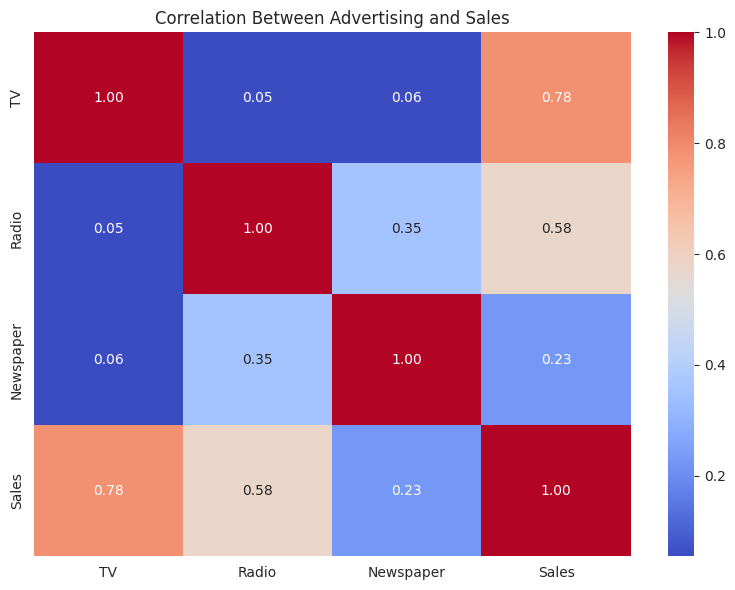

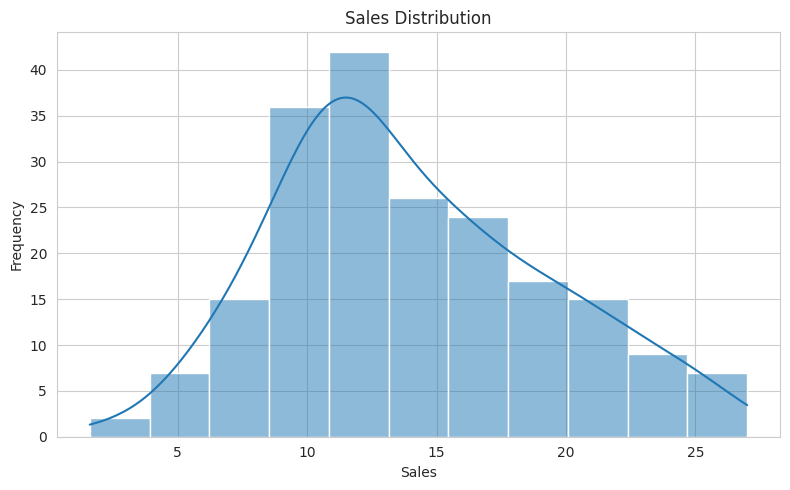

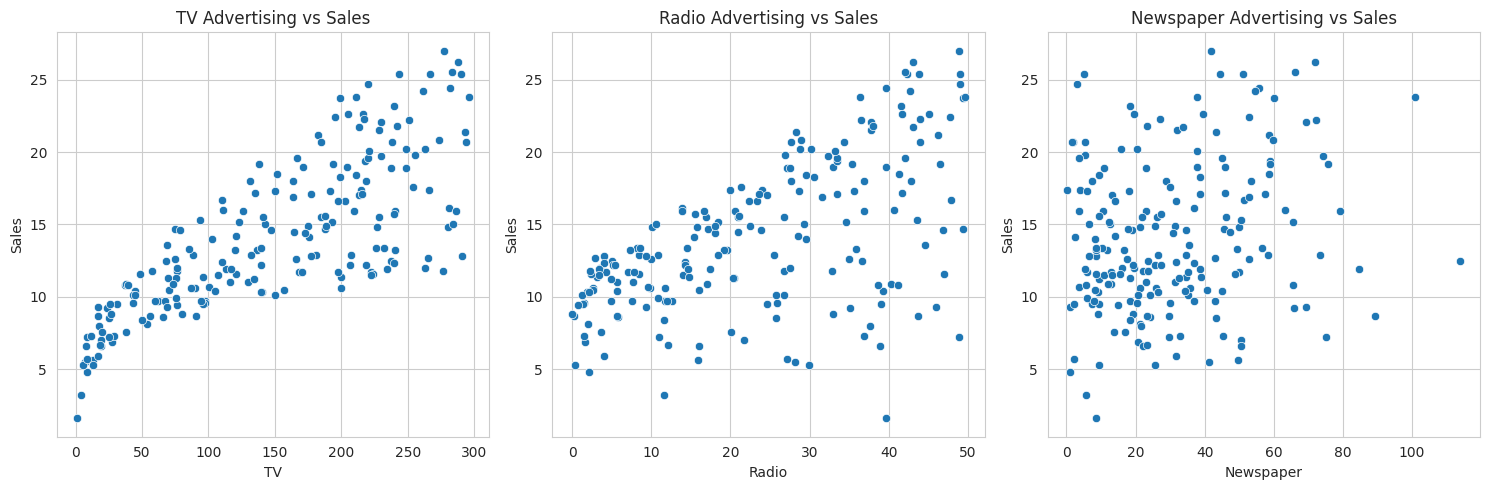

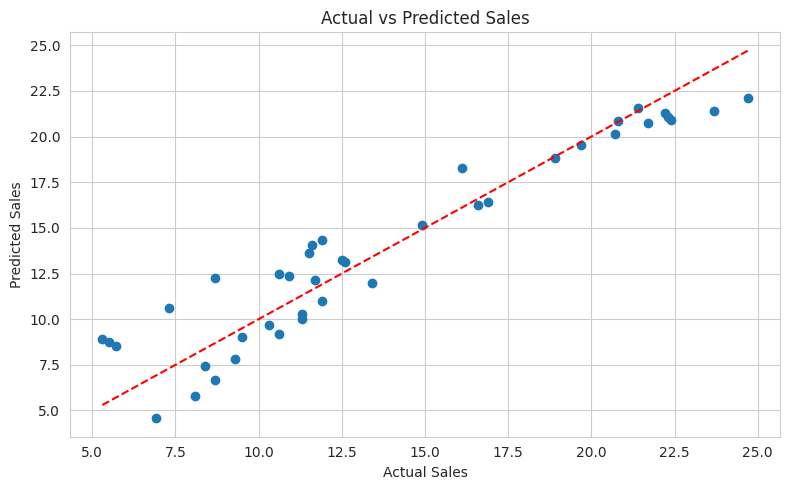

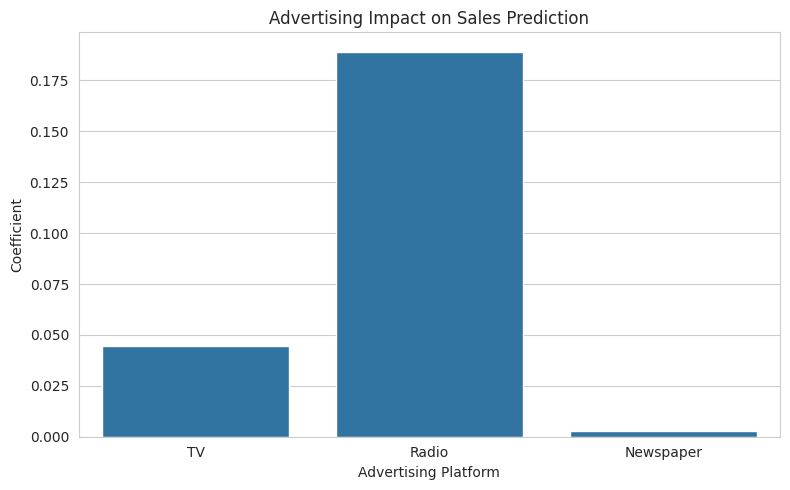


All visualization images saved successfully!

Saved Images:
['actual_vs_predicted.png', 'advertising_impact.png', 'sales_distribution.png', 'advertising_vs_sales.png', 'correlation_heatmap.png']


In [7]:

# ==========================================
# STEP 6: SAVE PROJECT VISUALIZATIONS
# ==========================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create images folder
os.makedirs('/content/images', exist_ok=True)

# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Between Advertising and Sales")
plt.tight_layout()
plt.savefig('/content/images/correlation_heatmap.png', dpi=300)
plt.show()

# 2. Sales Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['Sales'], kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig('/content/images/sales_distribution.png', dpi=300)
plt.show()

# 3. Advertising vs Sales
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, col in enumerate(['TV', 'Radio', 'Newspaper']):
    sns.scatterplot(data=df, x=col, y='Sales', ax=axes[i])
    axes[i].set_title(f'{col} Advertising vs Sales')

plt.tight_layout()
plt.savefig('/content/images/advertising_vs_sales.png', dpi=300)
plt.show()

# 4. Actual vs Predicted Sales
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.tight_layout()
plt.savefig('/content/images/actual_vs_predicted.png', dpi=300)
plt.show()

# 5. Advertising Impact
plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance,
    x='Advertising Platform',
    y='Coefficient'
)
plt.title("Advertising Impact on Sales Prediction")
plt.tight_layout()
plt.savefig('/content/images/advertising_impact.png', dpi=300)
plt.show()

print("\nAll visualization images saved successfully!")

print("\nSaved Images:")
print(os.listdir('/content/images'))


In [8]:

# Download all visualization images as ZIP

import shutil
from google.colab import files

shutil.make_archive(
    '/content/SalesPrediction_Images',
    'zip',
    '/content/images'
)

files.download('/content/SalesPrediction_Images.zip')

print("Images ZIP downloaded successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Images ZIP downloaded successfully!
